In [2]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [28]:
df = pd.read_csv('Telco_Customer_Churn_Cleaned.csv')

### Key Insights: Top 4 Categorical Drivers by Business Impact

- **1. Contract Type (`Month-to-month` — Impact Score: 37.8):** Accounts for **88.6%** of all churned customers with a **42.7%** internal churn rate. Lack of long-term commitment makes switching effortless compared to one- or two-year contract holders.
- **2. Internet Service (`Fiber optic` — Impact Score: 29.1):** Represents **69.4%** of total churn (**41.9%** churn rate). Despite offering higher speeds, Fiber optic users leave at a critical rate—pointing to dissatisfaction with higher pricing tiers, service stability, or strong competitor offers.
- **3. Online Security (`No` — Impact Score: 26.4):** Covers **84.2%** of all churned customers (**31.4%** churn rate), showing that subscribers without value-added security features have weaker product stickiness.
- **4. Tech Support (`No` — Impact Score: 26.1):** Accounts for **83.4%** of total churn (**31.2%** churn rate), highlighting that unresolved technical issues significantly accelerate customer exit.

**Actionable Recommendation:** Focus retention campaigns on high-volume **Month-to-month Fiber optic** subscribers by offering **annual contract discounts** and bundling free trial periods of **Online Security** and **Tech Support** to maximize retention impact.

In [51]:
cat_cols = [
    'gender', 'SeniorCitizen', 'Partner', 'Dependents',
    'PhoneService', 'MultipleLines', 'InternetService',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
    'TechSupport', 'StreamingTV', 'StreamingMovies',
    'Contract', 'PaperlessBilling', 'PaymentMethod'
]
churned_df = df[df['Churn'] == 'Yes']
not_churned_df = df[df['Churn'] == 'No']
def Chart_and_percentage(x):
    plt.figure(figsize=(10, 4))
    ax = sns.countplot(data=df, x=x, hue='Churn')
    plt.title(f'Churn by {x} Type')
    
    labels = [label.get_text().replace(' (', '\n(') for label in ax.get_xticklabels()]
    ax.set_xticklabels(labels)
    
    plt.tight_layout()
    plt.show()
    
    print('_'*50)
    print("\t who churned (Yes) \n", churned_df[x].value_counts(normalize=True) * 100)
    print()
    print("\t who not churned (No) \n", not_churned_df[x].value_counts(normalize=True) * 100)

In [62]:
top_risks = []
total_churned = (df['Churn'] == 'Yes').sum()

for col in cat_cols:
    ct = pd.crosstab(df[col], df['Churn'])
    rates = (ct['Yes'] / ct.sum(axis=1)) * 100
    
    top_cat = rates.idxmax()
    churn_rate = rates[top_cat]
    churn_share = (ct.loc[top_cat, 'Yes'] / total_churned) * 100
    impact_score = (churn_rate * churn_share) / 100
    
    top_risks.append([
        col, 
        top_cat, 
        round(churn_rate, 1), 
        round(churn_share, 1), 
        round(impact_score, 1)
    ])

risk_df = pd.DataFrame(top_risks, columns=['Column', 'Risk_Category', 'Churn_Rate', 'Churn_Share', 'Business_Impact'])
risk_df = risk_df.sort_values(by='Business_Impact', ascending=False).reset_index(drop=True)
display(risk_df)

,Column,Risk_Category,Churn_Rate,Churn_Share,Business_Impact
0,Contract,Month-to-month,42.7,88.6,37.8
1,InternetService,Fiber optic,41.9,69.4,29.1
2,OnlineSecurity,No,31.4,84.2,26.4
3,TechSupport,No,31.2,83.4,26.1
4,PaymentMethod,Electronic check,45.3,57.3,26.0
5,Dependents,No,31.3,82.6,25.8
6,PaperlessBilling,Yes,33.6,74.9,25.2
7,PhoneService,Yes,26.7,90.9,24.3
8,Partner,No,33.0,64.2,21.2
9,OnlineBackup,No,29.2,72.0,21.0


C:\Users\NOBEL\AppData\Local\Temp\ipykernel_5408\3840190158.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)


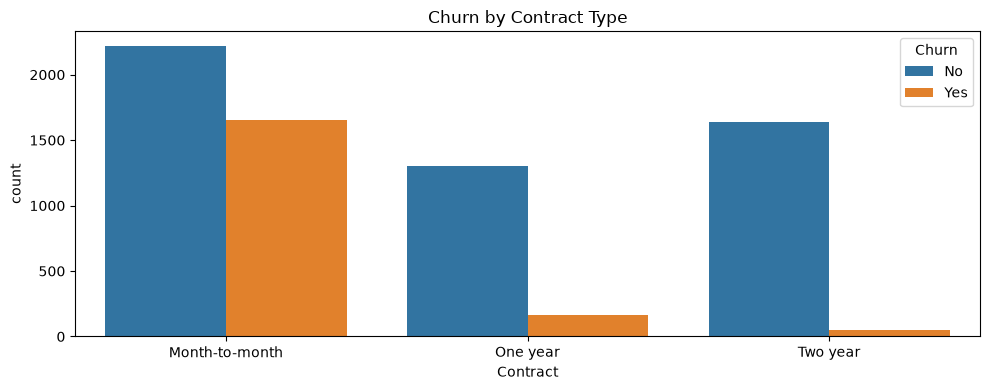

__________________________________________________
	 who churned (Yes) 
 Contract
Month-to-month    88.550027
One year           8.881755
Two year           2.568218
Name: proportion, dtype: float64

	 who not churned (No) 
 Contract
Month-to-month    42.998257
Two year          31.706372
One year          25.295371
Name: proportion, dtype: float64


In [58]:
Chart_and_percentage(cat_cols[13])

C:\Users\NOBEL\AppData\Local\Temp\ipykernel_5408\3840190158.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)


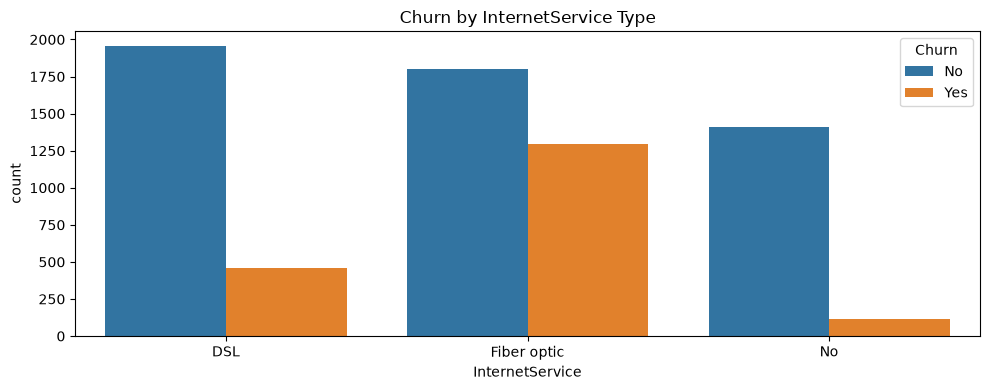

__________________________________________________
	 who churned (Yes) 
 InternetService
Fiber optic    69.395399
DSL            24.558587
No              6.046014
Name: proportion, dtype: float64

	 who not churned (No) 
 InternetService
DSL            37.904319
Fiber optic    34.844083
No             27.251598
Name: proportion, dtype: float64


In [59]:
Chart_and_percentage(cat_cols[6])

C:\Users\NOBEL\AppData\Local\Temp\ipykernel_5408\3840190158.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)


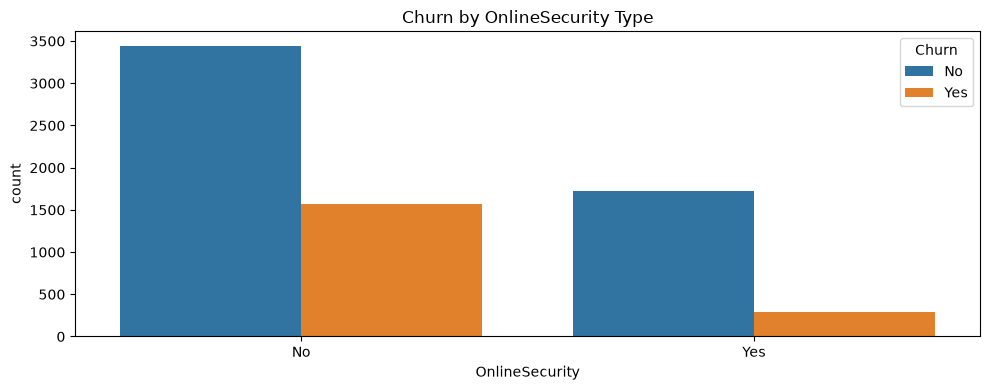

__________________________________________________
	 who churned (Yes) 
 OnlineSecurity
No     84.216158
Yes    15.783842
Name: proportion, dtype: float64

	 who not churned (No) 
 OnlineSecurity
No     66.686035
Yes    33.313965
Name: proportion, dtype: float64


In [60]:
Chart_and_percentage(cat_cols[7])

C:\Users\NOBEL\AppData\Local\Temp\ipykernel_5408\3840190158.py:16: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax.set_xticklabels(labels)


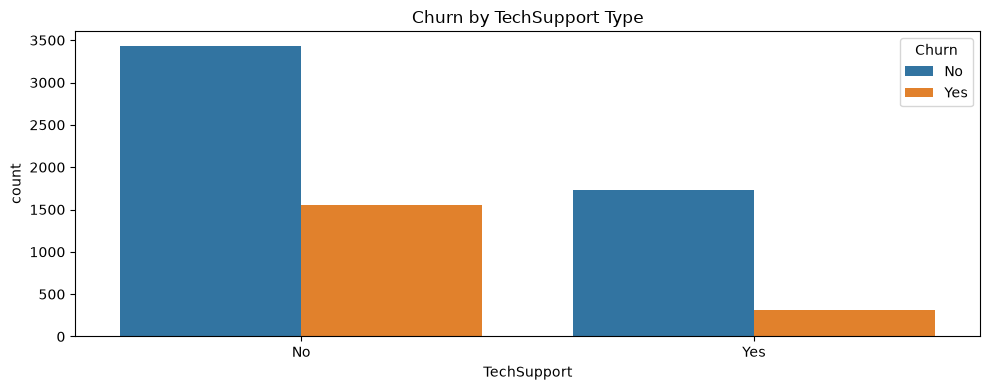

__________________________________________________
	 who churned (Yes) 
 TechSupport
No     83.41359
Yes    16.58641
Name: proportion, dtype: float64

	 who not churned (No) 
 TechSupport
No     66.492349
Yes    33.507651
Name: proportion, dtype: float64


In [61]:
Chart_and_percentage(cat_cols[10])

C:\Users\NOBEL\AppData\Local\Temp\ipykernel_5408\2826221745.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=top_4, x='Churn_Rate', y='Column', palette='Reds_r')


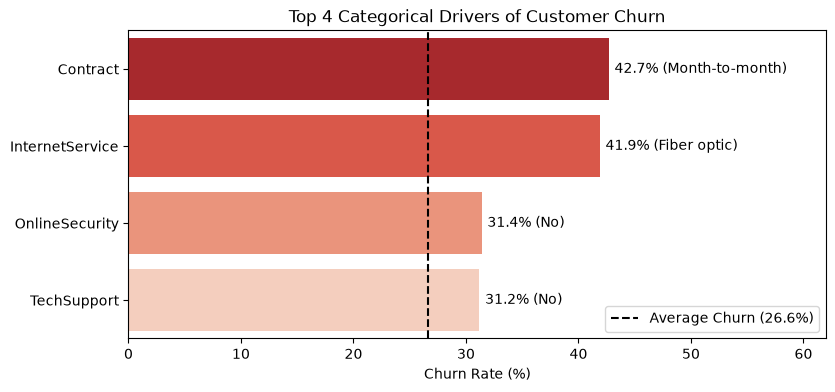

In [55]:
top_4 = risk_df.head(4)

plt.figure(figsize=(9, 4))

ax = sns.barplot(data=top_4, x='Churn_Rate', y='Column', palette='Reds_r')

plt.axvline(26.6, color='black', linestyle='--', label='Average Churn (26.6%)')

for i, row in enumerate(top_4.itertuples()):
    ax.text(row.Churn_Rate + 0.5, i, f"{row.Churn_Rate}% ({row.Risk_Category})", va='center', fontsize=10)

plt.xlim(0, 62)
plt.title('Top 4 Categorical Drivers of Customer Churn')
plt.xlabel('Churn Rate (%)')
plt.ylabel('')
plt.legend()
plt.show()

## Numerical Features Analysis
Exploring the distribution and relationship of numerical features (`tenure`, `MonthlyCharges`, `TotalCharges`) with customer churn.

In [30]:
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

In [40]:
def analyze_num(col):
    plt.figure(figsize=(9, 4))
    
    sns.kdeplot(data=df, x=col, hue='Churn', fill=True, common_norm=False, palette='Set2')
    plt.title(f'{col} - Density Distribution')
    
    plt.tight_layout()
    plt.show()
    
    print(df.groupby('Churn')[col].agg(['mean', 'median', 'std']).round(2))

### Insight: Customer Tenure (`tenure`)
* **Early Churn Spike:** The density curve shows a sharp peak in the **first 1–5 months** for churned customers, with a median tenure of just **10 months** (compared to **38 months** for retained customers).
* **Takeaway:** Customer loyalty builds significantly after the first year; onboarding and early-stage retention are critical.

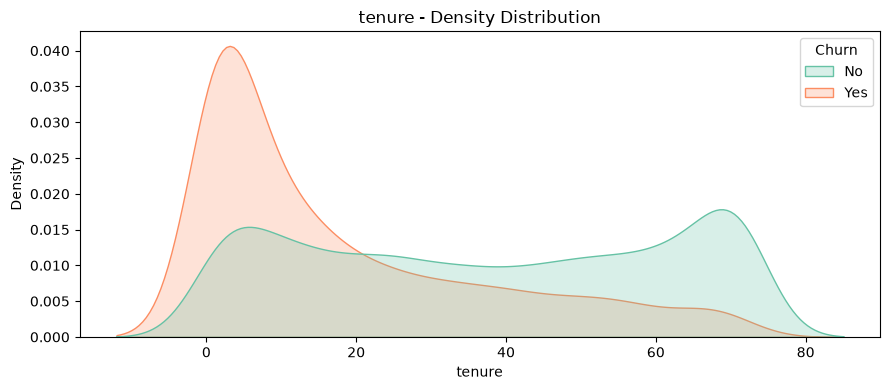

        mean  median    std
Churn                      
No     37.65    38.0  24.08
Yes    17.98    10.0  19.53


In [42]:
analyze_num('tenure')

### Insight: Monthly Charges (`MonthlyCharges`)
* **Price Sensitivity:** Churned customers cluster heavily in the **$70–$100/month** range (median **$79.65** vs. **$64.43** for non-churned), aligning with high-cost Fiber optic plans.
* **Takeaway:** Higher monthly bills strongly correlate with increased churn risk, especially without long-term contract discounts.

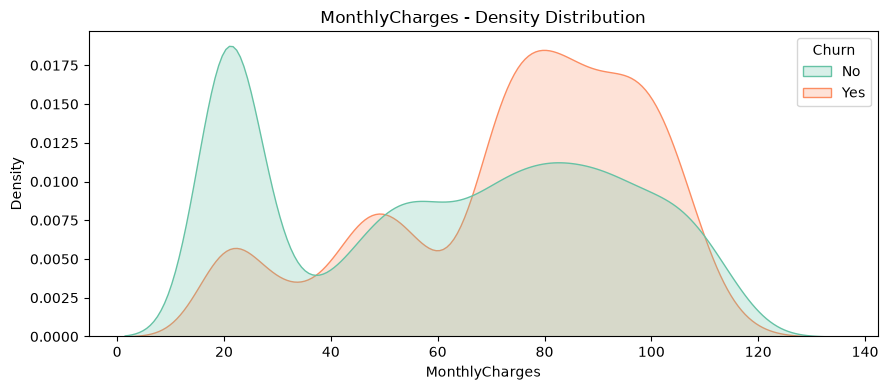

        mean  median    std
Churn                      
No     61.31   64.45  31.09
Yes    74.44   79.65  24.67


In [44]:
analyze_num('MonthlyCharges')

### Insight: Total Charges (`TotalCharges`)
* **Right-Skewed Early Exit:** Although churned users pay more per month, their total cumulative spend is much lower (median **~$703** vs. **~$1,683** for retained users) simply because they leave early in their lifecycle.
* **Takeaway:** `TotalCharges` is largely a function of `tenure × MonthlyCharges` rather than an independent churn driver.

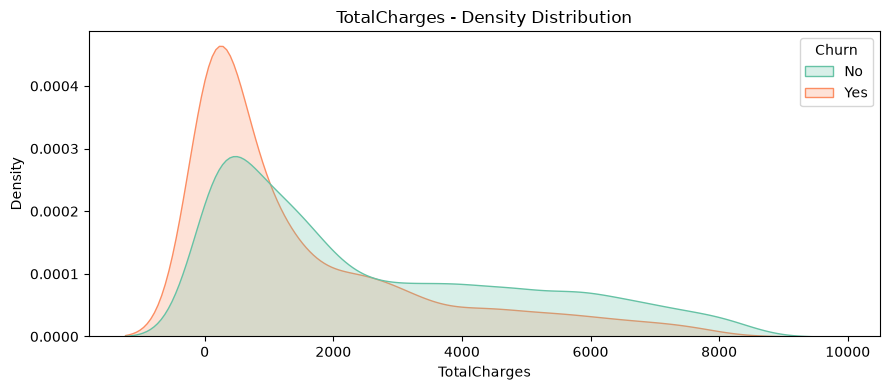

          mean   median      std
Churn                           
No     2555.34  1683.60  2329.46
Yes    1531.80   703.55  1890.82


In [50]:
analyze_num('TotalCharges')